# 04 — OULAD leakage-safe early-warning evaluation

This notebook evaluates an early-warning version of the enrollment-risk task. The target remains the final course outcome (`Fail`/`Withdrawn` versus `Pass`/`Distinction`), but each feature matrix is built as if the planner stopped observing the course at a specified course-relative day.

The evaluation uses three explicit safeguards:

1. assessment submissions and VLE activity after the cutoff are excluded;
2. future `date_unregistration` is excluded from cutoff features; and
3. the latest course presentation is held out as test data, so later presentations are not used to train earlier predictions.

This is an evaluation of early-warning feasibility, not a claim that a deployed planner would know the final outcome at prediction time.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.loader import load_oulad_tables
from src.data.cleaner import clean_oulad_tables
from src.features.feature_engineering import build_oulad_features
from src.models.baseline import (
    MODEL_NAMES,
    split_time_aware_data,
    train_time_aware_baselines,
)

DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'oulad'
CUTOFFS = [30, 60, 90]
tables = clean_oulad_tables(load_oulad_tables(DATA_DIR))
print(f'Loaded cleaned OULAD tables from {DATA_DIR}')

Loaded cleaned OULAD tables from D:\AI PROJECTS\C++\Smart-Study-Planner\data\processed\oulad


## Observation availability

The counts below show how much dated information exists by cutoff. Missing dates are not treated as observed evidence.

In [2]:
availability = []
for cutoff in CUTOFFS:
    availability.append({
        'cutoff_days': cutoff,
        'assessment_submissions_observed': int((tables['studentAssessment']['date_submitted'].notna() & (tables['studentAssessment']['date_submitted'] <= cutoff)).sum()),
        'vle_rows_observed': int((tables['studentVle']['date'].notna() & (tables['studentVle']['date'] <= cutoff)).sum()),
        'registrations_with_future_unregistration_excluded': int(tables['studentRegistration']['date_unregistration'].notna().sum()),
    })
availability_df = pd.DataFrame(availability)
display(availability_df.style.background_gradient(cmap='YlGnBu'))

,cutoff_days,assessment_submissions_observed,vle_rows_observed,registrations_with_future_unregistration_excluded
0,30,26522,2980575,10072
1,60,54744,4499256,10072
2,90,71051,5486878,10072


## Four-model time-aware evaluation

At each cutoff, the feature builder is rerun from the cleaned tables. The four baselines are logistic regression, random forest, extra-trees, and histogram gradient boosting. The model ranking is based on ROC-AUC, then balanced accuracy, then F1.

In [3]:
evaluation_rows = []
fitted_by_cutoff = {}
split_by_cutoff = {}
for cutoff in CUTOFFS:
    features = build_oulad_features(tables, clean=False, cutoff_days=cutoff)
    assert 'date_unregistration' not in features.columns
    best_name, fitted, model_results = train_time_aware_baselines(features)
    train_features, test_features, train_target, test_target = split_time_aware_data(features)
    fitted_by_cutoff[cutoff] = fitted
    split_by_cutoff[cutoff] = (test_features, test_target)
    for model_name in MODEL_NAMES:
        row = {'cutoff_days': cutoff, 'model': model_name, 'selected': model_name == best_name}
        row.update(model_results[model_name])
        evaluation_rows.append(row)

results = pd.DataFrame(evaluation_rows)
display(results.sort_values(['cutoff_days', 'roc_auc'], ascending=[True, False]).style.background_gradient(cmap='viridis', subset=['roc_auc', 'balanced_accuracy', 'f1']))

C:\Users\Rafi Sojan S\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


C:\Users\Rafi Sojan S\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


C:\Users\Rafi Sojan S\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,cutoff_days,model,selected,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,n_samples,n_train,n_test,random_state
1,30,random_forest,True,0.732682,0.732320,0.739004,0.744098,0.741542,0.815245,32593,21333,11260,42
3,30,hist_gradient_boosting,False,0.741030,0.741162,0.754810,0.736860,0.745727,0.806777,32593,21333,11260,42
2,30,extra_trees,False,0.723091,0.721643,0.715248,0.768740,0.741030,0.803825,32593,21333,11260,42
0,30,logistic_regression,False,0.725133,0.725412,0.741527,0.716354,0.728723,0.772451,32593,21333,11260,42
5,60,random_forest,True,0.767318,0.765984,0.756239,0.809409,0.781921,0.855580,32593,21333,11260,42
6,60,extra_trees,False,0.761368,0.759479,0.742982,0.820955,0.780025,0.852880,32593,21333,11260,42
7,60,hist_gradient_boosting,False,0.759858,0.758287,0.746148,0.809409,0.776492,0.846532,32593,21333,11260,42
4,60,logistic_regression,False,0.744938,0.742790,0.725427,0.812683,0.766580,0.814485,32593,21333,11260,42
9,90,random_forest,True,0.782948,0.781607,0.770059,0.825263,0.796706,0.877778,32593,21333,11260,42
10,90,extra_trees,False,0.779130,0.776700,0.750605,0.855764,0.799742,0.874997,32593,21333,11260,42


In [4]:
presentation_summary = []
for cutoff, (test_features, _) in split_by_cutoff.items():
    presentation_summary.append({
        'cutoff_days': cutoff,
        'train_presentations': ', '.join(sorted(set(tables['studentInfo']['code_presentation']) - set(test_features['code_presentation']))),
        'test_presentations': ', '.join(sorted(test_features['code_presentation'].unique())),
        'test_rows': len(test_features),
    })
display(pd.DataFrame(presentation_summary))
print('The default split holds out the latest available presentation at every cutoff.')

,cutoff_days,train_presentations,test_presentations,test_rows
0,30,"2013B, 2013J, 2014B",2014J,11260
1,60,"2013B, 2013J, 2014B",2014J,11260
2,90,"2013B, 2013J, 2014B",2014J,11260


The default split holds out the latest available presentation at every cutoff.


## Early-warning metric comparison

These plots show how performance changes as more course-relative observations become available. They should be read alongside the time-aware split and not compared directly with the retrospective full-course benchmark.

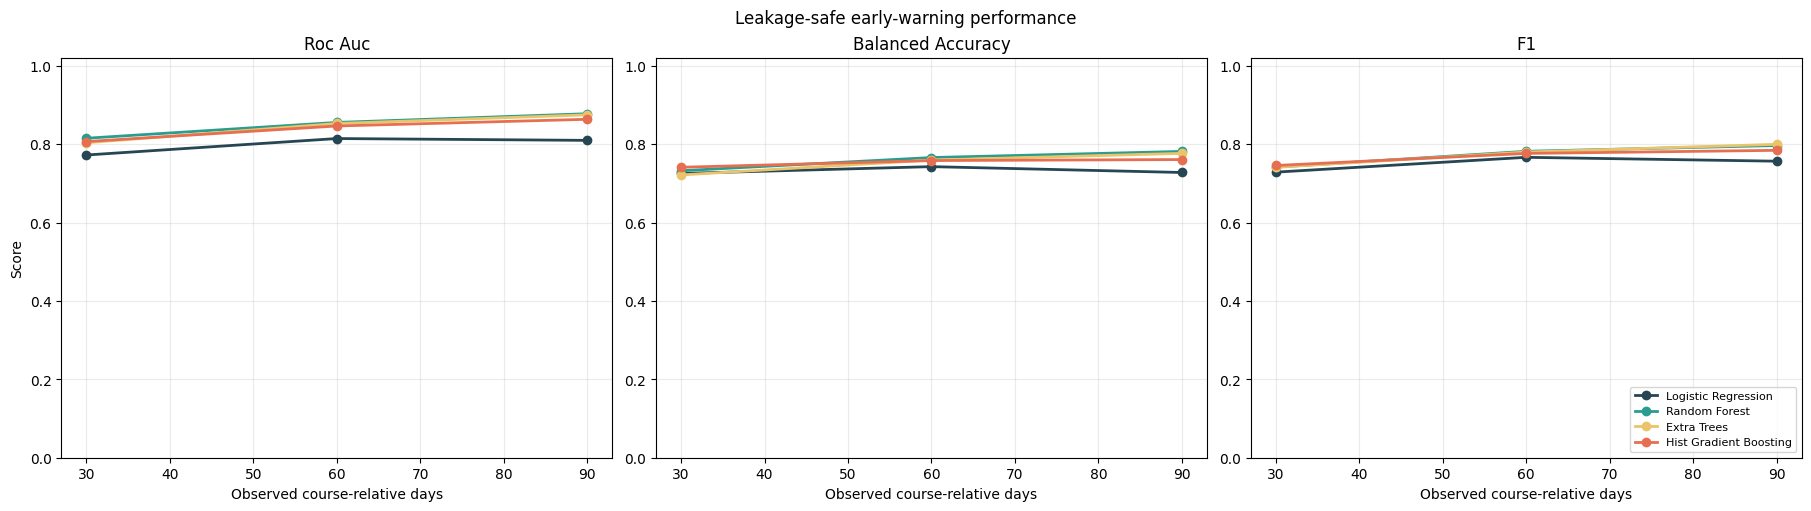

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
colors = {'logistic_regression': '#264653', 'random_forest': '#2a9d8f', 'extra_trees': '#e9c46a', 'hist_gradient_boosting': '#e76f51'}
for axis, metric in zip(axes, ['roc_auc', 'balanced_accuracy', 'f1']):
    for model_name in MODEL_NAMES:
        subset = results[results['model'] == model_name].sort_values('cutoff_days')
        axis.plot(subset['cutoff_days'], subset[metric], marker='o', linewidth=2, label=model_name.replace('_', ' ').title(), color=colors[model_name])
    axis.set_title(metric.replace('_', ' ').title())
    axis.set_xlabel('Observed course-relative days')
    axis.set_ylim(0, 1.02)
    axis.grid(alpha=0.25)
axes[0].set_ylabel('Score')
axes[-1].legend(loc='lower right', fontsize=8)
fig.suptitle('Leakage-safe early-warning performance')
plt.show()

## Confusion matrices at every early-warning cutoff

Confusion matrices make the operational trade-off visible at 30, 60 and 90 observed course-relative days: false negatives are learners at risk that the planner failed to flag, while false positives are learners flagged for support who ultimately were not in the risk class.

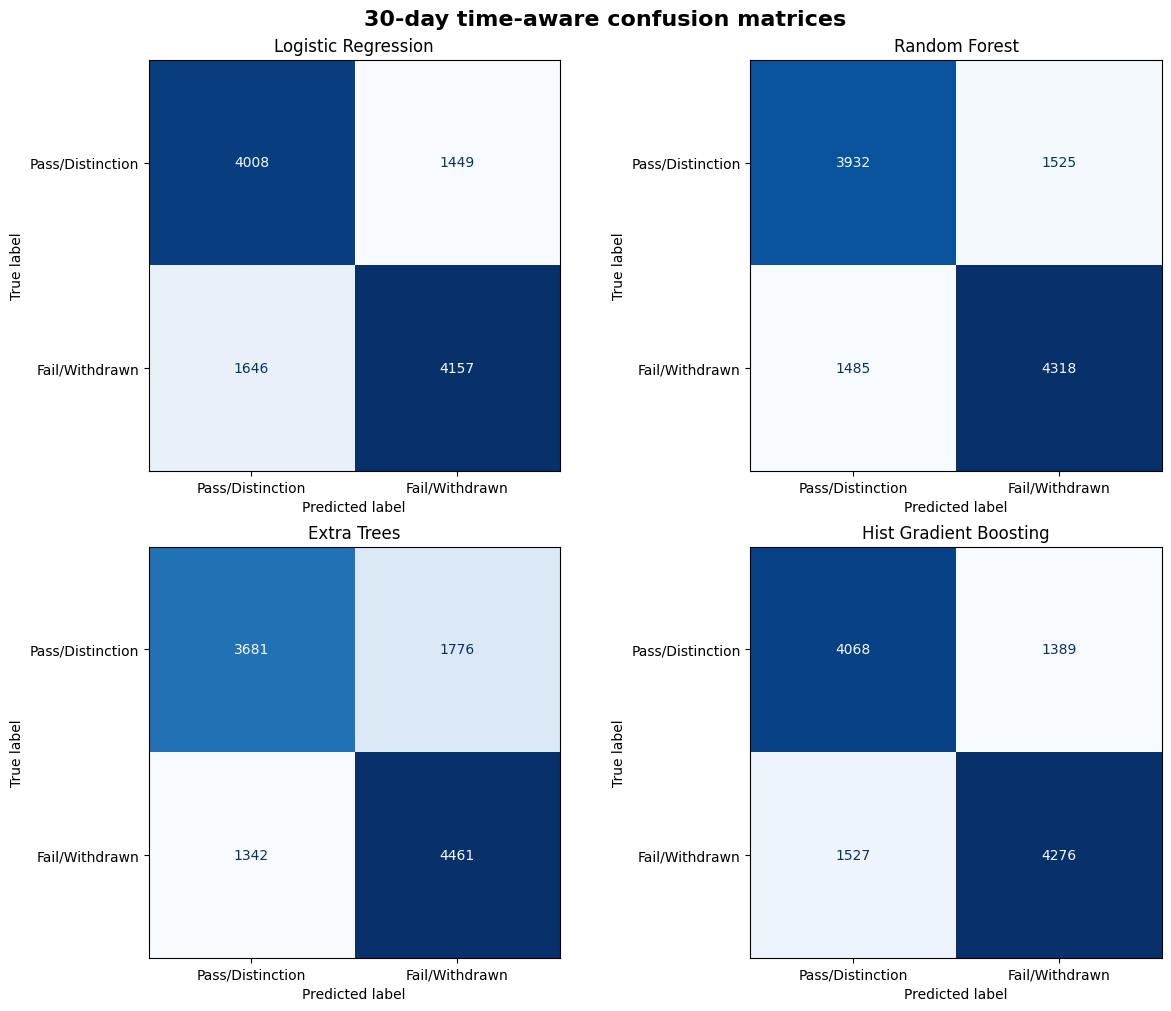

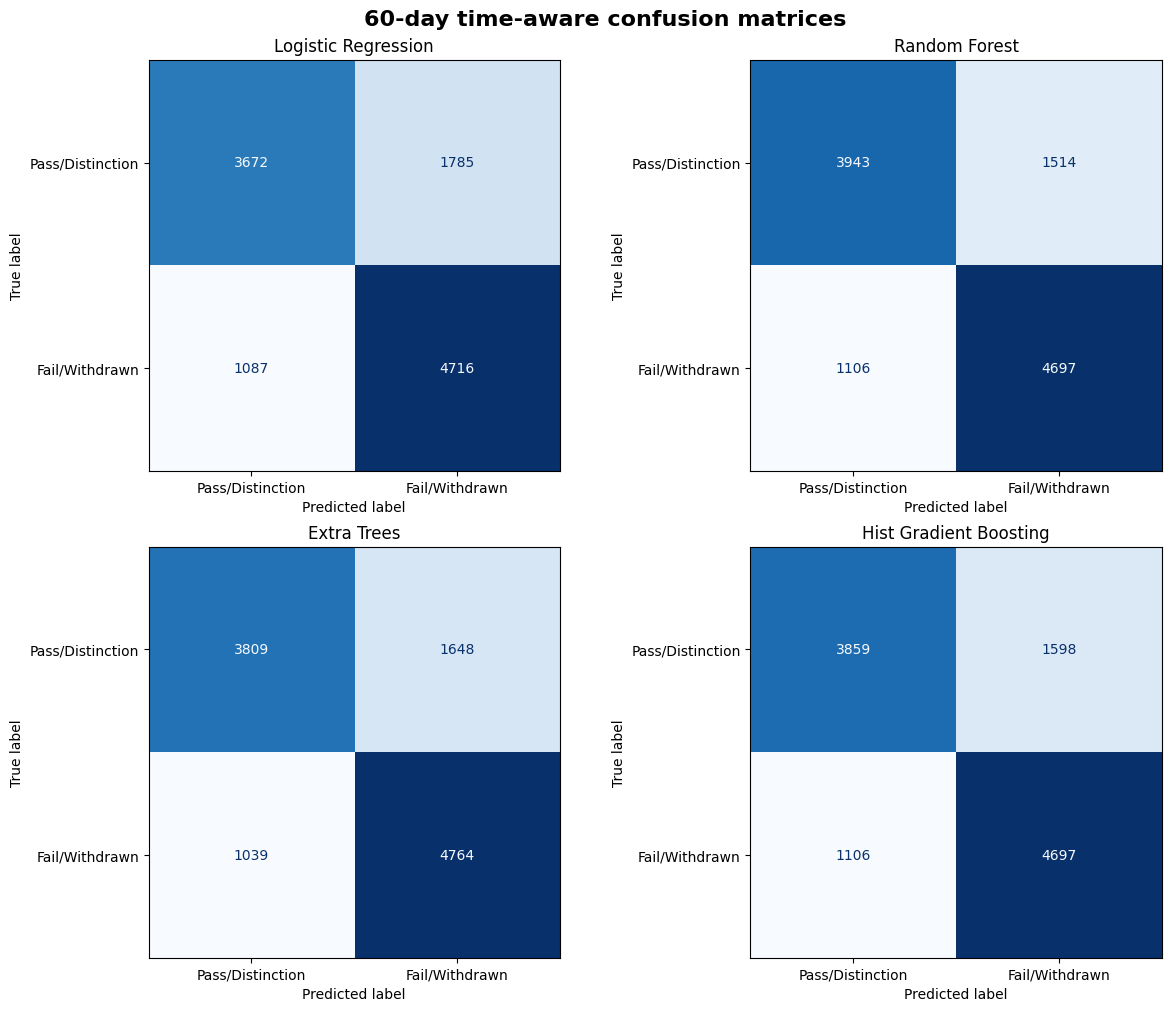

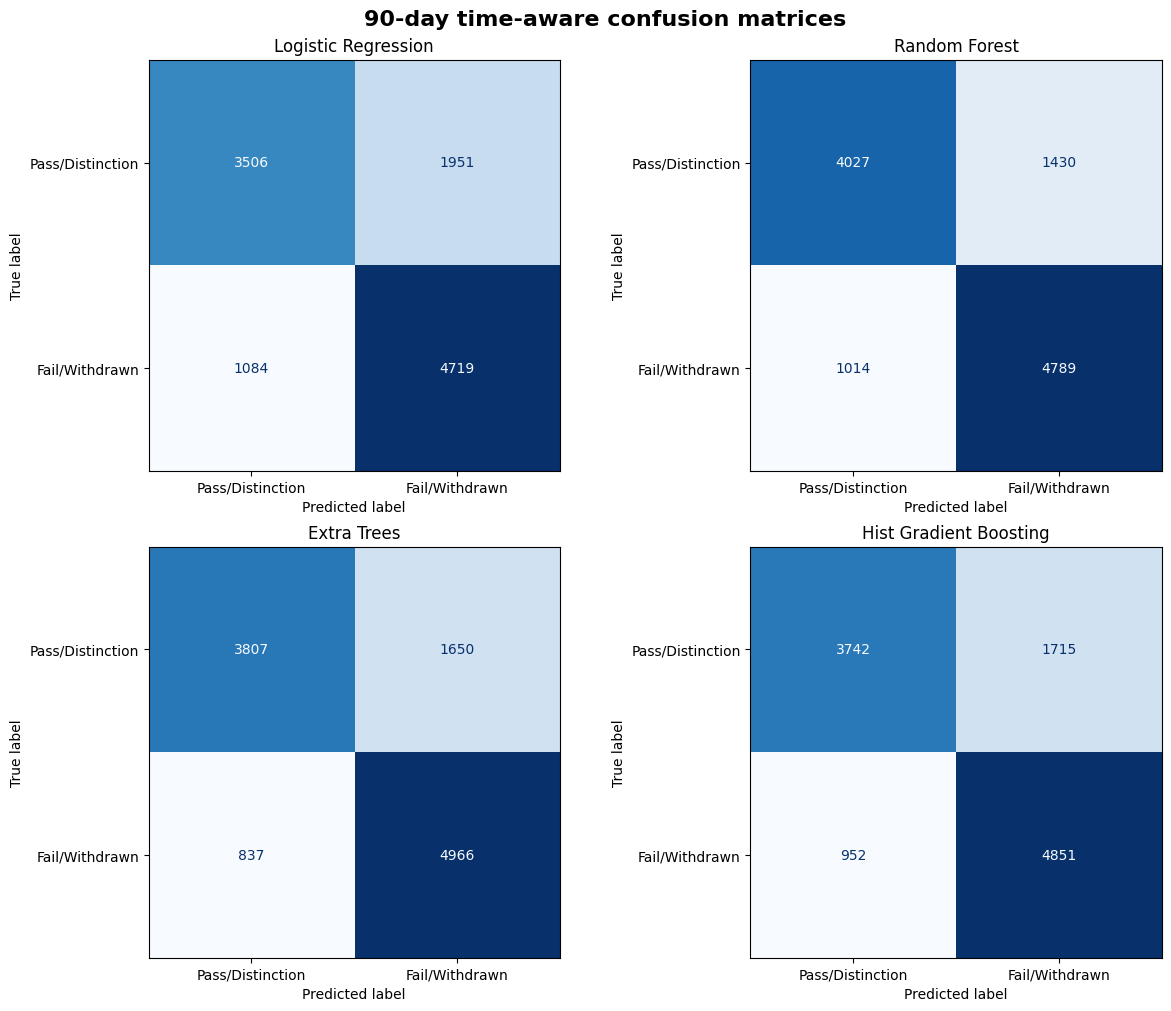

In [6]:
for cutoff in CUTOFFS:
    test_features, test_target = split_by_cutoff[cutoff]
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
    for axis, model_name in zip(axes.ravel(), MODEL_NAMES):
        ConfusionMatrixDisplay.from_estimator(
            fitted_by_cutoff[cutoff][model_name],
            test_features,
            test_target,
            display_labels=['Pass/Distinction', 'Fail/Withdrawn'],
            cmap='Blues',
            colorbar=False,
            ax=axis,
        )
        axis.set_title(model_name.replace('_', ' ').title())
    fig.suptitle(f'{cutoff}-day time-aware confusion matrices', fontsize=16, weight='bold')
    plt.show()

## Interpretation and limitations

The selected model and scores must be taken from the executed result table or the reproducible JSON output generated by `pipeline/early_warning_pipeline.py`; this notebook does not hard-code metrics.

This design still uses the final course outcome as the label, so it measures retrospective discrimination under an early-observation constraint. A production study planner would need prospective validation, intervention-aware evaluation, calibration and threshold selection, and a policy for handling learners with too little observed activity.